# Продолжение банкета

## Импорты

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import optuna
import kagglehub
import glob

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

SEED = 67
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Выделяем нужные фичи

In [69]:
TARGET = "actual_delivery_time_minutes"
BENCHMARK = "estimated_delivery_time_minutes"      # ETA платформы: только бенчмарк, не признак

CORE_NUM = ["distance_km", "restaurant_preparation_time_minutes",
            "delivery_partner_experience_months", "delivery_partner_rating"]
CORE_CAT = ["traffic_level", "weather"] # по core сделаем бейзлайн
CONTEXT_NUM = ["order_hour", "is_weekend", "customer_age", "restaurant_rating",
               "items_count", "subtotal", "discount_percent", "delivery_fee"]
CONTEXT_CAT = ["day_of_week", "city", "delivery_area", "customer_type",
               "restaurant_type", "restaurant_primary_category", "payment_method"]
INPUT_COLS = CORE_NUM + CORE_CAT + CONTEXT_NUM + CONTEXT_CAT

Делим датасет и фильтруем, как показано в EDA

In [70]:
CSV_NAME = "food_delivery_orders_dataset.csv"
folder = kagglehub.dataset_download("razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset")
df = pd.read_csv(glob.glob(f"{folder}/**/{CSV_NAME}", recursive=True)[0])
df = df[df['order_status'] == 'Completed'].reset_index(drop=True)
X, y = df[INPUT_COLS], df[TARGET]
X_train, X_test, y_train, y_test, eta_train, eta_test = train_test_split(
    X, y, df[BENCHMARK], test_size=0.2, random_state=SEED)

Вспомогательные функции

In [71]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

def within_5(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 5)

SCORING = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "within5": make_scorer(within_5),
}

def cv_eval(estimator, name, Xd=None, yd=None): 
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    r = cross_validate(estimator, Xd, yd, cv=CV, scoring=SCORING)
    return {"model": name,
            "MAE": -r["test_mae"].mean(), "MAE std": r["test_mae"].std(),
            "RMSE": -r["test_rmse"].mean(), "≤5 min": r["test_within5"].mean()}

def show(rows, base=None): #сравниваем с бейзлайном  
    t = pd.DataFrame(rows).set_index("model")
    if base is not None:
        t["Δ MAE"] = base - t["MAE"]
    return t.round(3)

def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "≤5 min": within_5(y_true, y_pred)}

bench_train = metrics(y_train, eta_train)
pd.Series(bench_train, name="ETA from data (train)").round(3).to_frame().T

,MAE,RMSE,≤5 min
ETA from data (train),5.226,6.894,0.616


## Добавляем новые фичи

In [72]:
TRAFFIC_ORDER = ["Low", "Medium", "High"]
WEATHER_ORDER = ["Clear", "Cloudy", "Rain", "Storm"]

def add_features(frame):
    f = frame.copy()
    f["traffic_ord"] = f["traffic_level"].map({k: i + 1 for i, k in enumerate(TRAFFIC_ORDER)}) # нумеруем с 1
    f["weather_ord"] = f["weather"].map({k: i + 1 for i, k in enumerate(WEATHER_ORDER)})
    f["dist_x_traffic"] = f["distance_km"] * f["traffic_ord"]
    f["dist_x_weather"] = f["distance_km"] * f["weather_ord"]
    return f

NEW_FEATURES = ['dist_x_traffic', 'dist_x_weather']

SETS = {
    "core": dict(num=CORE_NUM, cat=CORE_CAT),
    "core + new features": dict(num=CORE_NUM + NEW_FEATURES, cat=CORE_CAT),
    "full": dict(num=CORE_NUM + NEW_FEATURES + CONTEXT_NUM, cat=CORE_CAT + CONTEXT_CAT)
}

In [73]:
def make_pipeline(model, features="core + new_features", scaler=None):
    spec = SETS[features]
    num_steps = []
    if scaler is not None:
        num_steps.append(("scale", clone(scaler)))
    parts = [
        ("num", Pipeline(num_steps) if num_steps else "passthrough", spec["num"]),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(spec["cat"])),
    ]
    return Pipeline([("add_features", FunctionTransformer(add_features)),
                     ("scale + encode", ColumnTransformer(parts)),
                     ("model", model)])


make_pipeline(Ridge(1), "core")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('add_features', ...), ('scale + encode', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...0029EB9F36CF0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=N

## Baseline

In [74]:
rows = [
    cv_eval(make_pipeline(DummyRegressor(strategy="median"), "core"), "Dummy"),
    cv_eval(make_pipeline(Ridge(alpha=1.0), "core", scaler=StandardScaler()), "Ridge, core"),
    cv_eval(make_pipeline(HistGradientBoostingRegressor(random_state=SEED), "core"), "HistGradientBoosting, core"),
]
rows.append({"model": "ETA платформы (бенчмарк)", "MAE": bench_train["MAE"], "MAE std": np.nan,
             "RMSE": bench_train["RMSE"], "≤5 min": bench_train["≤5 min"]})
res_base = show(rows)
BASE_MAE = res_base.loc["Ridge, core", "MAE"]
res_base

,MAE,MAE std,RMSE,≤5 min
model,,,,
Dummy,10.810,0.10,14.846,0.337
"Ridge, core",2.755,0.02,3.749,0.862
"HistGradientBoosting, core",2.078,0.01,2.629,0.946
ETA платформы (бенчмарк),5.226,NaN,6.894,0.616


In [75]:
rows = []
for fs in SETS:
    rows.append(cv_eval(make_pipeline(Ridge(alpha=1.0), fs, scaler=StandardScaler()), f"Ridge | {fs}"))
for fs in SETS:
    rows.append(cv_eval(make_pipeline(HistGradientBoostingRegressor(random_state=SEED), fs), f"HGB | {fs}"))
res_fs = show(rows, base=BASE_MAE)
res_fs

,MAE,MAE std,RMSE,≤5 min,Δ MAE
model,,,,,
Ridge | core,2.755,0.020,3.749,0.862,-0.000
Ridge | core + new features,2.091,0.013,2.642,0.944,0.664
Ridge | full,2.093,0.013,2.644,0.944,0.662
HGB | core,2.078,0.010,2.629,0.946,0.677
HGB | core + new features,2.084,0.014,2.632,0.945,0.671
HGB | full,2.092,0.013,2.647,0.945,0.663


В целом для линейной регрессии получилось, что новые фичи улучшают перформанс. Если расширить набор фичей до полного, то улучшения нет. Градиентный бустинг показывает лучший результат c базовым набором фичей, но core + new features ещё лежит в пределах стандартного отклонения.

Сравним разные алгоритмы на одном сете фичей.

In [76]:
BEST_SET = "core + new features"
rows = [
    cv_eval(make_pipeline(Ridge(alpha=1.0), BEST_SET, scaler=StandardScaler()), "Ridge"),
    cv_eval(make_pipeline(RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5,
                                            random_state=SEED, n_jobs=-1), BEST_SET), "RandomForest"),
    cv_eval(make_pipeline(HistGradientBoostingRegressor(random_state=SEED), BEST_SET), "HistGradientBoosting"),
]
res_models = show(rows, base=BASE_MAE)
res_models

,MAE,MAE std,RMSE,≤5 min,Δ MAE
model,,,,,
Ridge,2.091,0.013,2.642,0.944,0.664
RandomForest,2.165,0.008,2.826,0.935,0.590
HistGradientBoosting,2.084,0.014,2.632,0.945,0.671


Выберем градиентный бустинг, но ridge тоже на GridSearch посмотрим, вдруг что-то да выйдет

In [77]:
base_hgb = make_pipeline(HistGradientBoostingRegressor(random_state=SEED), BEST_SET)
hgb_default = cv_eval(base_hgb, "HGB, по умолчанию")

grid = GridSearchCV(
    make_pipeline(HistGradientBoostingRegressor(random_state=SEED), BEST_SET),
    param_grid={"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31, 63],
                "model__min_samples_leaf": [20, 100]},
    cv=CV, scoring="neg_mean_absolute_error", n_jobs=1, refit=True)
grid.fit(X_train, y_train)
print("GridSearchCV:", grid.best_params_, "| CV MAE =", round(-grid.best_score_, 4))

GridSearchCV: {'model__learning_rate': 0.05, 'model__max_leaf_nodes': 63, 'model__min_samples_leaf': 20} | CV MAE = 2.0799


Randomized Search и Оптуну будем запускать на всех трёх сетах.

In [78]:
rand = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingRegressor(random_state=SEED), BEST_SET),
    param_distributions={
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1, 0.15],
        "model__max_iter": [200, 400, 600],
        "model__max_leaf_nodes": [8, 15, 31, 63],
        "model__min_samples_leaf": [10, 20, 50, 100, 200],
        "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    },
    n_iter=15, cv=CV, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, refit=True)
rand.fit(X_train, y_train)
print("RandomizedSearchCV:", rand.best_params_, "| CV MAE =", round(-rand.best_score_, 4))

RandomizedSearchCV: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 31, 'model__max_iter': 600, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0} | CV MAE = 2.0612


In [79]:
rand_full = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingRegressor(random_state=SEED), "full"),
    param_distributions={
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1, 0.15],
        "model__max_iter": [200, 400, 600],
        "model__max_leaf_nodes": [8, 15, 31, 63],
        "model__min_samples_leaf": [10, 20, 50, 100, 200],
        "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    },
    n_iter=15, cv=CV, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, refit=True)
rand_full.fit(X_train, y_train)
print("RandomizedSearchCV - full features:", rand_full.best_params_, "| CV MAE =", round(-rand_full.best_score_, 4))

RandomizedSearchCV - full features: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 31, 'model__max_iter': 600, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0} | CV MAE = 2.0698


In [80]:
rand_core = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingRegressor(random_state=SEED), "core"),
    param_distributions={
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1, 0.15],
        "model__max_iter": [200, 400, 600],
        "model__max_leaf_nodes": [8, 15, 31, 63],
        "model__min_samples_leaf": [10, 20, 50, 100, 200],
        "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    },
    n_iter=15, cv=CV, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, refit=True)
rand_core.fit(X_train, y_train)
print("RandomizedSearchCV_core:", rand_core.best_params_, "| CV MAE =", round(-rand_core.best_score_, 4))

RandomizedSearchCV_core: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__max_iter': 600, 'model__learning_rate': 0.02, 'model__l2_regularization': 0.0} | CV MAE = 2.0589


In [81]:
from functools import partial

def objective(trial, features=BEST_SET):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_iter": trial.suggest_int("max_iter", 200, 600, step=100),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 63),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 200, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 10.0, log=True),
    }
    pipe = make_pipeline(HistGradientBoostingRegressor(random_state=SEED, **params), features)
    r = cross_validate(pipe, X_train, y_train, cv=CV, scoring="neg_mean_absolute_error")
    return -r["test_score"].mean()

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=25)
print("Optuna:", study.best_params, "| CV MAE =", round(study.best_value, 4))

Optuna: {'learning_rate': 0.03300976813664051, 'max_iter': 500, 'max_leaf_nodes': 40, 'min_samples_leaf': 11, 'l2_regularization': 0.04246108407361091} | CV MAE = 2.0628


In [82]:
study_full = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_full.optimize(partial(objective, features="full"), n_trials=25)
print("Optuna:", study_full.best_params, "| CV MAE =", round(study_full.best_value, 4))

Optuna: {'learning_rate': 0.02513915508345009, 'max_iter': 300, 'max_leaf_nodes': 43, 'min_samples_leaf': 13, 'l2_regularization': 0.17660556151633594} | CV MAE = 2.0715


In [83]:
study_core = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_core.optimize(partial(objective, features="core"), n_trials=25)
print("Optuna:", study_core.best_params, "| CV MAE =", round(study_core.best_value, 4))

Optuna: {'learning_rate': 0.021967865411533144, 'max_iter': 400, 'max_leaf_nodes': 42, 'min_samples_leaf': 11, 'l2_regularization': 0.21052894393792743} | CV MAE = 2.0626


Смотрим что в итоге получилось

In [84]:
best_models = {
    "HGB baseline": make_pipeline(HistGradientBoostingRegressor(random_state=SEED), BEST_SET),
    "GridSearchCV": grid.best_estimator_,
    "RandomizedSearchCV": rand.best_estimator_,
    "RandomizedSearchCV_full": rand_full.best_estimator_,
    "RandomizedSearchCV_core": rand_core.best_estimator_,
    "Optuna selected features": make_pipeline(HistGradientBoostingRegressor(random_state=SEED, **study.best_params), BEST_SET),
    "Optuna full features": make_pipeline(HistGradientBoostingRegressor(random_state=SEED, **study_full.best_params), "full"),
    "Optuna core features": make_pipeline(HistGradientBoostingRegressor(random_state=SEED, **study_core.best_params), "core")
}
rows = [cv_eval(clone(m), name) for name, m in best_models.items()]
res_tune = show(rows, base=hgb_default["MAE"])
res_tune

,MAE,MAE std,RMSE,≤5 min,Δ MAE
model,,,,,
HGB baseline,2.084,0.014,2.632,0.945,0.000
GridSearchCV,2.080,0.015,2.644,0.946,0.004
RandomizedSearchCV,2.061,0.014,2.601,0.948,0.023
RandomizedSearchCV_full,2.070,0.012,2.615,0.947,0.014
RandomizedSearchCV_core,2.059,0.012,2.604,0.947,0.025
Optuna selected features,2.063,0.014,2.604,0.947,0.021
Optuna full features,2.071,0.011,2.620,0.947,0.013
Optuna core features,2.063,0.015,2.607,0.948,0.021


Давайте и для линейной регресси тоже запустим, чем чёрт не шутит

In [85]:
ridge_grid = GridSearchCV(make_pipeline(Ridge(), BEST_SET, scaler=StandardScaler()),
                          param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                          cv=CV, scoring="neg_mean_absolute_error", refit=True)
ridge_grid.fit(X_train, y_train)
pd.DataFrame({"alpha": ridge_grid.cv_results_["param_model__alpha"],
              "CV MAE": -ridge_grid.cv_results_["mean_test_score"],
              "std": ridge_grid.cv_results_["std_test_score"]}).round(4)

,alpha,CV MAE,std
0,0.01,2.0907,0.0126
1,0.10,2.0907,0.0126
2,1.00,2.0907,0.0126
3,10.00,2.0906,0.0125
4,100.00,2.0904,0.0122
5,1000.00,2.1129,0.0120


Улучшений нет

In [86]:
cv_table = res_tune["MAE"]
best_name = cv_table.idxmin()
final_model = clone(best_models[best_name]).fit(X_train, y_train)
pred = final_model.predict(X_test)

final = pd.DataFrame({
    "ETA платформы": metrics(y_test, eta_test),
    "Ridge (baseline, core)": metrics(y_test, make_pipeline(Ridge(alpha=1.0), "core", scaler=StandardScaler()).fit(X_train, y_train).predict(X_test)),
    "HGB, по умолчанию": metrics(y_test, clone(best_models["HGB baseline"]).fit(X_train, y_train).predict(X_test)),
    f"Финальная модель: {best_name}": metrics(y_test, pred),
}).T.round(3)
print("Выбрана по CV:", best_name)
final

Выбрана по CV: RandomizedSearchCV_core


,MAE,RMSE,≤5 min
ETA платформы,5.318,7.078,0.615
"Ridge (baseline, core)",2.756,3.791,0.864
"HGB, по умолчанию",2.104,2.652,0.941
Финальная модель: RandomizedSearchCV_core,2.086,2.629,0.945


**Вывод**: финальная модель - градиентный бустинг, с параметрами, подобранными RandomizedSearchCV. Улучшение MAE более чем в 2 раза относительно ETA в данных, доля доставок с опозданием <= 5 минут выросла на 33 процентных пункта, до 94,5%.

Добавление новых фич не улучшило модель, все изменения в итоговом результате можно обьяснить шумом.

In [87]:
#этот приколдес тоже иишка
test = X_test.assign(y=y_test.values, pred=pred, eta=eta_test.values)
test["err_model"] = (test["y"] - test["pred"]).abs()
test["err_eta"] = (test["y"] - test["eta"]).abs()
test["dist_bin"] = pd.cut(test["distance_km"], [0, 2, 4, 6, 8, 10, 20])

seg = pd.concat([
    test.groupby("traffic_level")[["err_model", "err_eta"]].mean(),
    test.groupby("weather")[["err_model", "err_eta"]].mean(),
    test.groupby("dist_bin", observed=True)[["err_model", "err_eta"]].mean(),
]).round(2)
seg.columns = ["MAE модели", "MAE платформы"]
seg

,MAE модели,MAE платформы
High,2.10,5.77
Low,2.04,4.98
Medium,2.11,5.23
Clear,2.07,3.97
Cloudy,2.09,4.97
Rain,2.07,8.81
Storm,2.57,16.20
"(0, 2]",1.95,4.31
"(2, 4]",2.09,4.72
"(4, 6]",2.06,5.34


**Вывод**: Ошибка ровная по сегментам, в отличии от ETA из данных, которые завышены на сложных погодных условиях.

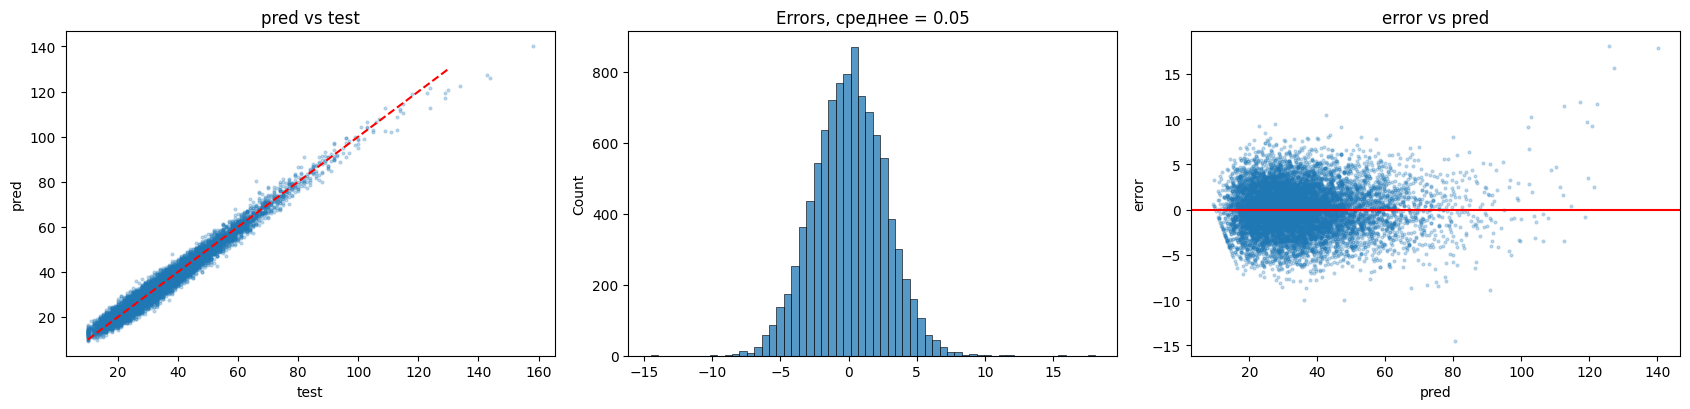

In [88]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].scatter(test["y"], test["pred"], s=4, alpha=.25); ax[0].plot([10, 130], [10, 130], "r--")
ax[0].set_xlabel("test"); ax[0].set_ylabel("pred"); ax[0].set_title("pred vs test")
resid = test["y"] - test["pred"]
sns.histplot(resid, bins=60, ax=ax[1]); ax[1].set_title(f"Errors, среднее = {resid.mean():.2f}")
ax[2].scatter(test["pred"], resid, s=4, alpha=.25); ax[2].axhline(0, color="r")
ax[2].set_xlabel("pred"); ax[2].set_ylabel("error"); ax[2].set_title("error vs pred")
plt.tight_layout(); plt.show()

Ошибка распределена равномерно

               distance_km  restaurant_preparation_time_minutes  traffic_level  weather  delivery_partner_experience_months  delivery_partner_rating
рост MAE, мин        9.593                                6.112          2.709    1.555                                 0.0                      0.0


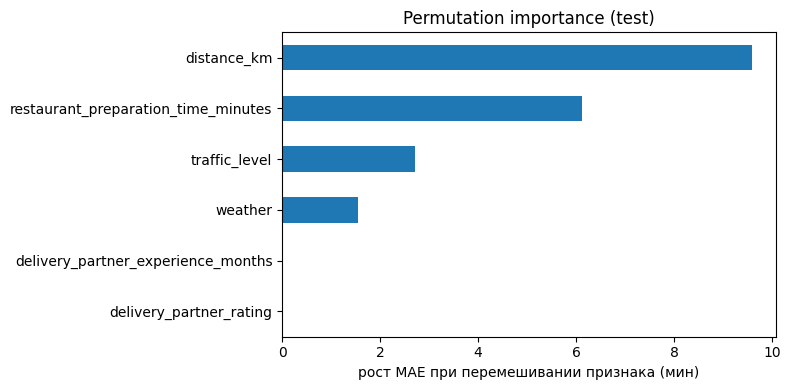

In [89]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test[INPUT_COLS], y_test, scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=INPUT_COLS).sort_values(ascending=False)
used = SETS['core']["num"] + SETS['core']["cat"]
imp_used = imp[[c for c in imp.index if c in used]]
print(imp_used.round(3).to_frame("рост MAE, мин").T.to_string())
fig, ax = plt.subplots(figsize=(8, 4))
imp_used.sort_values().plot.barh(ax=ax)
ax.set_xlabel("рост MAE при перемешивании признака (мин)"); ax.set_title("Permutation importance (test)")
plt.tight_layout(); plt.show()

Видно, что признаки, связанные с курьером, не влияют на ответ, так что их тоже можно было отцепить.

## Дополнительно, на подумать

Вполне возможно, что MAE - не совсем та метрика, которую мы действительно хотим минимизировать. Что лучше - приложение которое достаточно хорошо предсказывает ETA, но при этом в половине случаев ошибается в сторону опоздания, или которое предсказывает ETA чуть хуже, но при этом эта ошибка наоборот за счёт того что ETA чуть завышается, и уменьшает долю опозданий? Это скорее продуктовый вопрос. Первый случай уже реализован, на основании этого можно сделать и второй, при помощи квантильного лосса.

In [90]:
def promise_metrics(y_true, y_pred):
    d = np.asarray(y_true) - np.asarray(y_pred)          # d > 0: order arrived later than promised
    return {"MAE": np.abs(d).mean(),
            "RMSE": np.sqrt((d ** 2).mean()),
            "late rate": (d > 0).mean(),
            "mean lateness, min": np.maximum(d, 0).mean(),    
            "mean earliness, min": np.maximum(-d, 0).mean()}

TUNED = {k.removeprefix("model__"): v for k, v in rand_core.best_params_.items()}

def hgb_pipe(**kw):
    return make_pipeline(HistGradientBoostingRegressor(random_state=SEED, **TUNED, **kw), "core")

def cv_promise(estimator, name):
    parts = []
    for tr, va in CV.split(X_train):
        m = clone(estimator).fit(X_train.iloc[tr], y_train.iloc[tr])
        parts.append(promise_metrics(y_train.iloc[va], m.predict(X_train.iloc[va])))
    return pd.DataFrame(parts).mean().rename(name)

platform = pd.Series(promise_metrics(y_train, eta_train), name="Platform ETA (train)")
cv_loss = pd.concat([
    platform,
    cv_promise(hgb_pipe(), "squared_error"),
    cv_promise(hgb_pipe(loss="quantile", quantile=0.8), "quantile q = 0.8"),
    cv_promise(hgb_pipe(loss="quantile", quantile=0.9), "quantile q = 0.9"),
], axis=1).T
cv_loss.round(3)

,MAE,RMSE,late rate,"mean lateness, min","mean earliness, min"
Platform ETA (train),5.226,6.894,0.759,4.717,0.508
squared_error,2.059,2.604,0.496,1.029,1.030
quantile q = 0.8,2.794,3.459,0.207,0.314,2.479
quantile q = 0.9,3.579,4.259,0.106,0.143,3.436


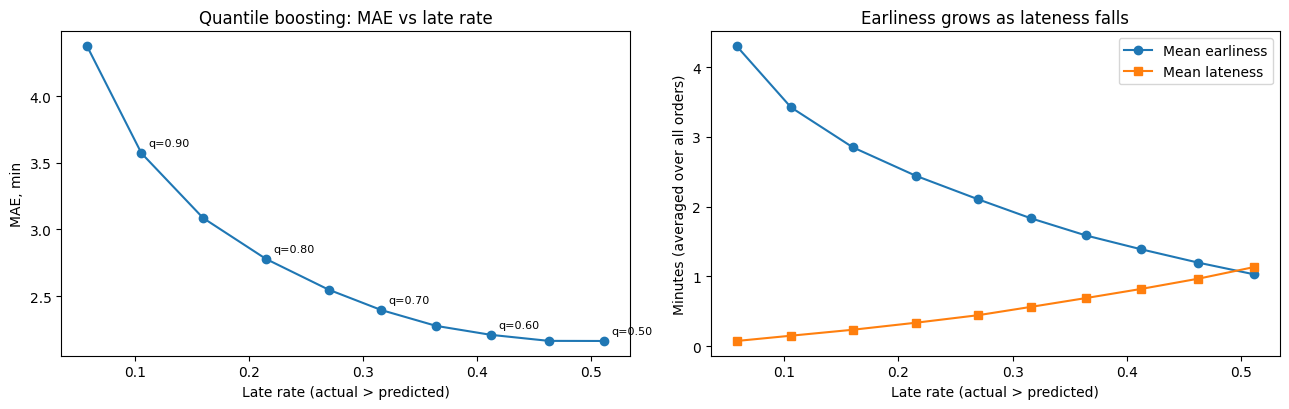

,MAE,RMSE,late rate,"mean lateness, min","mean earliness, min"
q,,,,,
0.50,2.163,2.839,0.511,1.134,1.029
0.55,2.163,2.847,0.463,0.967,1.196
0.60,2.209,2.859,0.412,0.818,1.390
0.65,2.276,2.923,0.364,0.689,1.587
0.70,2.395,3.042,0.316,0.562,1.832
0.75,2.548,3.213,0.270,0.443,2.105
0.80,2.778,3.453,0.215,0.334,2.444
0.85,3.086,3.776,0.160,0.234,2.852
0.90,3.572,4.265,0.106,0.149,3.424


In [91]:
qs = np.round(np.arange(0.50, 0.96, 0.05), 2)

qhgb_models = {q: hgb_pipe(loss="quantile", quantile=q).fit(X_train, y_train) for q in qs}
frontier = pd.DataFrame([
    {**promise_metrics(y_test, qhgb_models[q].predict(X_test)), "q": q} for q in qs
])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

ax[0].plot(frontier["late rate"], frontier["MAE"], "o-")
for _, r in frontier.iloc[::2].iterrows():
    ax[0].annotate(f"q={r['q']:.2f}", (r["late rate"], r["MAE"]),
                   textcoords="offset points", xytext=(5, 5), fontsize=8)
ax[0].set_xlabel("Late rate (actual > predicted)")
ax[0].set_ylabel("MAE, min")
ax[0].set_title("Quantile boosting: MAE vs late rate")

ax[1].plot(frontier["late rate"], frontier["mean earliness, min"], "o-", label="Mean earliness")
ax[1].plot(frontier["late rate"], frontier["mean lateness, min"], "s-", label="Mean lateness")
ax[1].set_xlabel("Late rate (actual > predicted)")
ax[1].set_ylabel("Minutes (averaged over all orders)")
ax[1].set_title("Earliness grows as lateness falls")
ax[1].legend()

plt.tight_layout()
plt.show()
frontier.set_index("q").round(3)

## Итоги

- Финальная модель (HistGradientBoosting, подбор RandomizedGridSearch) на hold-out: MAE = 2,086 мин против 5,318 у ETA платформы (−61 %), доля заказов с ошибкой ≤ 5 мин — 94,5 % против 61,5 %.
- Линейная Ridge с признаками-взаимодействиями (`distance × traffic`, `distance x weather`) почти не уступает бустингу  и полностью интерпретируема.
- Ключевые признаки — дистанция, время приготовления, пробки и погода; характеристики курьера не влияют.
- Асимметрия: если опоздание дороже опережения, прогноз сдвигается на квантиль остатков. Например, при 10 % опозданий MAE растёт до 3,58 мин, но среднее опоздание падает с 1,03 до 0,14 мин.